# Exploratory analysis: Adult Income

This notebook looks at the data before any model is built. The questions:

1. What does the raw data look like, and what must be cleaned?
2. How unbalanced is the target?
3. Which columns relate to income, and what does that mean for the features?

Run `python scripts/download_data.py` first. The notebook only reads files; it changes nothing.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from tabular_prediction.cleaning import clean
from tabular_prediction.config import CATEGORICAL_FEATURES, TARGET
from tabular_prediction.data import load_raw
from tabular_prediction.errors import with_bands

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
raw = load_raw(ROOT / "data" / "raw")
print(raw.shape)
raw.head()

(48842, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## 1. The raw data

Every column is read as text. Missing values are written as `?`, and the two source files write the target differently.

In [2]:
print("Income labels as written in the files:")
print(raw["income"].value_counts().to_string())
print()
print("Cells equal to '?', by column:")
marks = (raw == "?").sum()
print(marks[marks > 0].to_string())
print()
print("Exact duplicate rows (ignoring the full stop in the label):", raw.assign(income=raw["income"].str.rstrip(".")).duplicated().sum())

Income labels as written in the files:
income
<=50K     24720
<=50K.    12435
>50K       7841
>50K.      3846

Cells equal to '?', by column:
workclass         2799
occupation        2809
native_country     857

Exact duplicate rows (ignoring the full stop in the label): 52


In [3]:
frame, report = clean(raw)
print(report)
frame.describe().round(2)

CleaningReport(rows_in=48842, duplicate_rows_removed=52, rows_out=48790, missing_by_column={'workclass': 2795, 'occupation': 2805, 'native_country': 856}, positive_share=0.23941381430621028)


,age,education_num,hours_per_week,capital_gain,capital_loss,income_over_50k
count,48790.00,48790.00,48790.00,48790.00,48790.00,48790.00
mean,38.65,10.08,40.43,1080.22,87.60,0.24
std,13.71,2.57,12.39,7455.91,403.21,0.43
min,17.00,1.00,1.00,0.00,0.00,0.00
25%,28.00,9.00,40.00,0.00,0.00,0.00
50%,37.00,10.00,40.00,0.00,0.00,0.00
75%,48.00,12.00,45.00,0.00,0.00,0.00
max,90.00,16.00,99.00,99999.00,4356.00,1.00


## 2. The target

In [4]:
share = frame[TARGET].mean()
print(f"Above 50K: {share:.1%} of {len(frame):,} people")
print(f"A model that always answers '50K or less' is right {1 - share:.1%} of the time.")

Above 50K: 23.9% of 48,790 people
A model that always answers '50K or less' is right 76.1% of the time.


## 3. Numbers and income

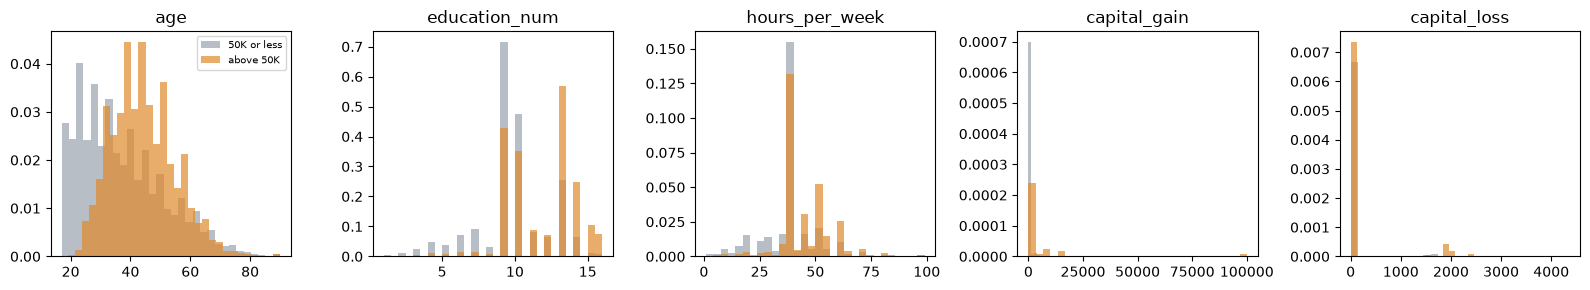

In [5]:
numbers = ["age", "education_num", "hours_per_week", "capital_gain", "capital_loss"]
figure, axes = plt.subplots(1, 5, figsize=(16, 3))
for axis, column in zip(axes, numbers):
    for value, colour, label in ((0, "#9aa3ad", "50K or less"), (1, "#e08a2c", "above 50K")):
        axis.hist(frame.loc[frame[TARGET] == value, column], bins=30, alpha=0.7, color=colour, label=label, density=True)
    axis.set_title(column)
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

In [6]:
zero = (frame[["capital_gain", "capital_loss"]] == 0).mean()
print("Share of people with a value of zero:")
print(zero.map("{:.1%}".format).to_string())
print()
print("Share above 50K, with and without a capital gain:")
print(frame.groupby(frame["capital_gain"] > 0)[TARGET].mean().map("{:.1%}".format).to_string())
print()
print("Correlation of each number with the target:")
print(frame[numbers + [TARGET]].corr()[TARGET].drop(TARGET).round(3).to_string())

Share of people with a value of zero:
capital_gain    91.7%
capital_loss    95.3%

Share above 50K, with and without a capital gain:
capital_gain
False    20.5%
True     61.7%

Correlation of each number with the target:
age               0.230
education_num     0.333
hours_per_week    0.228
capital_gain      0.223
capital_loss      0.148


## 4. Categories and income

In [7]:
for column in CATEGORICAL_FEATURES:
    table = frame.fillna({column: "(missing)"}).groupby(column)[TARGET].agg(people="size", above_50k="mean")
    table["above_50k"] = table["above_50k"].map("{:.1%}".format)
    print(table.sort_values("people", ascending=False).head(8).to_string())
    print()

                  people above_50k
workclass                         
Private            33860     21.8%
Self-emp-not-inc    3861     27.9%
Local-gov           3136     29.6%
(missing)           2795      9.5%
State-gov           1981     26.8%
Self-emp-inc        1694     55.4%
Federal-gov         1432     39.2%
Without-pay           21      9.5%

                       people above_50k
marital_status                         
Married-civ-spouse      22366     44.6%
Never-married           16082      4.6%
Divorced                 6630     10.1%
Separated                1530      6.5%
Widowed                  1518      8.4%
Married-spouse-absent     627      9.3%
Married-AF-spouse          37     37.8%

                   people above_50k
occupation                         
Prof-specialty       6165     45.1%
Craft-repair         6102     22.6%
Exec-managerial      6082     47.8%
Adm-clerical         5606     13.7%
Sales                5501     26.8%
Other-service        4919      4.1%


In [8]:
rare = {column: int((frame[column].value_counts(normalize=True) < 0.01).sum()) for column in CATEGORICAL_FEATURES}
print("Categories that cover less than 1% of the people, by column:")
print(pd.Series(rare).to_string())

Categories that cover less than 1% of the people, by column:
workclass          2
marital_status     1
occupation         2
relationship       0
race               2
sex                0
native_country    39


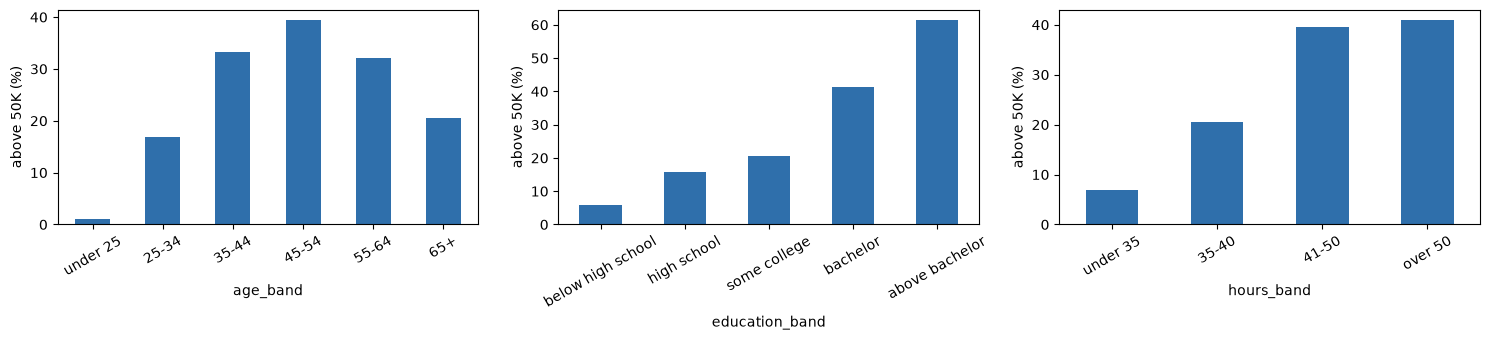

In [9]:
banded = with_bands(frame)
figure, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for axis, column in zip(axes, ("age_band", "education_band", "hours_band")):
    (banded.groupby(column, observed=True)[TARGET].mean() * 100).plot.bar(ax=axis, color="#2f6fab")
    axis.set_ylabel("above 50K (%)")
    axis.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

## What this means for the pipeline

The points below are read from the outputs above.

- **Cleaning:** trim the text, turn `?` into missing values (only `workclass`, `occupation` and `native_country` have them), remove the full stop from the labels of the second file, and drop the few exact duplicate rows.
- **Target:** about one person in four earns above 50K. Accuracy alone would flatter a model, so F1, ROC AUC and the probability errors are reported too, next to a baseline.
- **Capital gain and loss:** zero for most people, with a long tail, and a gain goes with a much higher share of high incomes. They get a `log(1 + x)` transform before scaling.
- **Education:** `education` and `education_num` say the same thing, so only the number is kept. `fnlwgt` is a census sampling weight and is dropped.
- **Categories:** `native_country` has many rare values. Categories under 1% of the rows are grouped, and missing values become their own category, because "missing" may itself carry information.
- **Age, education and hours** all relate to income, and not in a straight line (age rises and then falls). That favours tree models over a plain linear one.